In [2]:
import pandas as pd
data={
    "date":["2026-08-01", "2026-08-02", "2026-08-03", "2026-08-04", "2026-08-05"],
    "demand":[20, 25, 22, 31, 28]
}
df=pd.DataFrame(data)
df
df["demand"].mean()


np.float64(25.2)

In [3]:
df["date"]=pd.to_datetime(df["date"])

In [4]:
df.dtypes

date      datetime64[us]
demand             int64
dtype: object

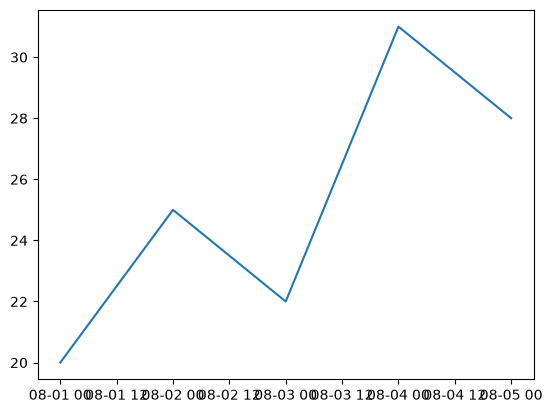

In [5]:
import matplotlib.pyplot as plt
plt.plot(df["date"],df["demand"])
plt.show()

In [6]:
import pandas as pd
sample_df=pd.read_csv(
    "../data/favorita/favorita-grocery-sales-forecasting/train.csv",
    nrows=10
)
sample_df

,id,date,store_nbr,item_nbr,unit_sales,onpromotion
0,0,2013-01-01,25,103665,7.0,NaN
1,1,2013-01-01,25,105574,1.0,NaN
2,2,2013-01-01,25,105575,2.0,NaN
3,3,2013-01-01,25,108079,1.0,NaN
4,4,2013-01-01,25,108701,1.0,NaN
5,5,2013-01-01,25,108786,3.0,NaN
6,6,2013-01-01,25,108797,1.0,NaN
7,7,2013-01-01,25,108952,1.0,NaN
8,8,2013-01-01,25,111397,13.0,NaN
9,9,2013-01-01,25,114790,3.0,NaN


In [7]:
import pandas as pd
df = pd.read_csv(
    "../data/favorita/favorita-grocery-sales-forecasting/train.csv",
    nrows=100000
)
df["date"] = pd.to_datetime(df["date"])

df.shape
df.dtypes


id                      int64
date           datetime64[us]
store_nbr               int64
item_nbr                int64
unit_sales            float64
onpromotion           float64
dtype: object

In [8]:
df["date"].min(), df["date"].max()

(Timestamp('2013-01-01 00:00:00'), Timestamp('2013-01-04 00:00:00'))

In [9]:
df["store_nbr"].nunique()
df["item_nbr"].nunique()

1592

In [10]:
df["unit_sales"].describe()

count    100000.000000
mean         10.021255
std          17.370912
min         -27.000000
25%           2.000000
50%           5.000000
75%          11.000000
max         608.909000
Name: unit_sales, dtype: float64

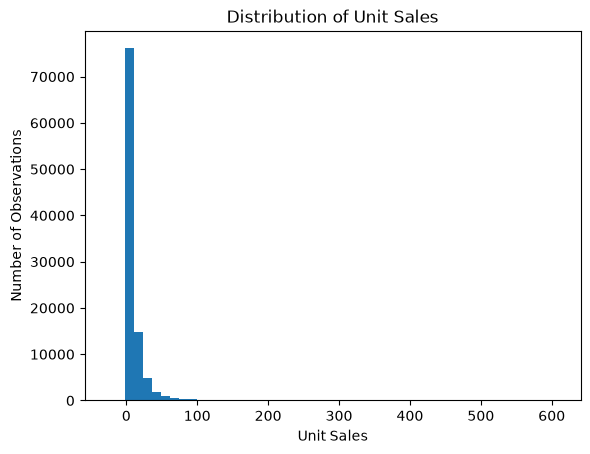

In [11]:
import matplotlib.pyplot as plt
plt.hist(df["unit_sales"], bins=50)
plt.xlabel("Unit Sales")
plt.ylabel("Number of Observations")
plt.title("Distribution of Unit Sales")
plt.show()

In [12]:
df[["store_nbr","item_nbr"]].head(10)

,store_nbr,item_nbr
0,25,103665
1,25,105574
2,25,105575
3,25,108079
4,25,108701
5,25,108786
6,25,108797
7,25,108952
8,25,111397
9,25,114790


In [13]:
file_path = "../data/favorita/favorita-grocery-sales-forecasting/train.csv"

In [14]:
chunks = pd.read_csv(
    file_path,
    chunksize=100000
)

In [15]:
matching_rows = []

for chunk in chunks:
    filtered = chunk[
        (chunk["store_nbr"] == 25) &
        (chunk["item_nbr"] == 103665)
    ]

    matching_rows.append(filtered)

In [16]:
type(matching_rows[0])

pandas.DataFrame

In [17]:
series_df = pd.concat(matching_rows, ignore_index=True)

In [18]:
series_df.shape

(1142, 6)

In [19]:
series_df.head()

,id,date,store_nbr,item_nbr,unit_sales,onpromotion
0,0,2013-01-01,25,103665,7.0,NaN
1,19811,2013-01-02,25,103665,5.0,NaN
2,100696,2013-01-04,25,103665,5.0,NaN
3,141831,2013-01-05,25,103665,5.0,NaN
4,183815,2013-01-06,25,103665,7.0,NaN


In [20]:
series_df["date"].min(), series_df["date"].max()

('2013-01-01', '2017-08-15')

In [21]:
series_df.dtypes

id               int64
date               str
store_nbr        int64
item_nbr         int64
unit_sales     float64
onpromotion     object
dtype: object

In [22]:
series_df["date"] = pd.to_datetime(series_df["date"])

In [23]:
series_df.dtypes

id                      int64
date           datetime64[us]
store_nbr               int64
item_nbr                int64
unit_sales            float64
onpromotion            object
dtype: object

In [24]:
# Find the earliest and latest dates for this store-item series
start_date = series_df["date"].min()
end_date = series_df["date"].max()

# Calculate how many calendar days exist between those two dates
total_days = (end_date - start_date).days + 1

# Number of actual rows we have
actual_rows = len(series_df)

# Difference between possible calendar days and available rows
missing_days = total_days - actual_rows

print("Start date:", start_date)
print("End date:", end_date)
print("Total calendar days:", total_days)
print("Actual rows:", actual_rows)
print("Potential missing days:", missing_days)

Start date: 2013-01-01 00:00:00
End date: 2017-08-15 00:00:00
Total calendar days: 1688
Actual rows: 1142
Potential missing days: 546


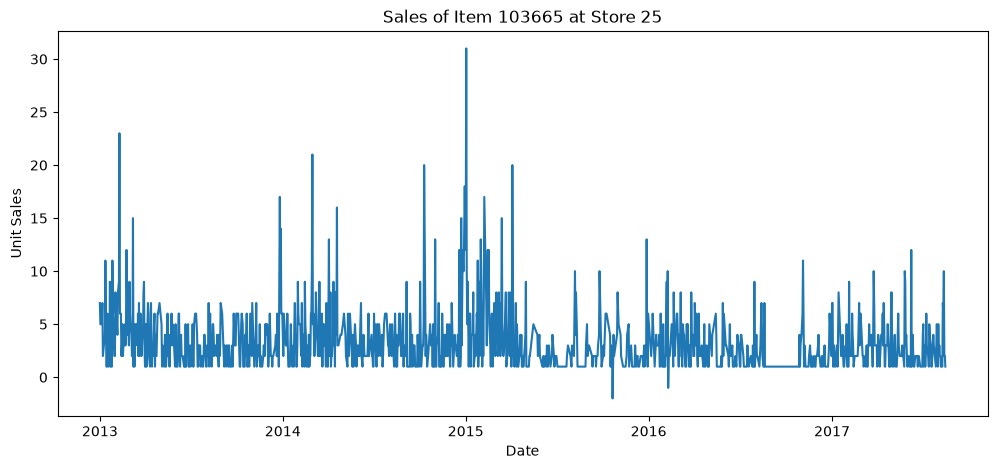

In [25]:
# Plot the historical sales for this specific store-item combination
plt.figure(figsize=(12, 5))

plt.plot(
    series_df["date"],
    series_df["unit_sales"]
)

plt.xlabel("Date")
plt.ylabel("Unit Sales")
plt.title("Sales of Item 103665 at Store 25")

plt.show()

In [26]:
# Create every calendar date between the first and last date
all_dates = pd.date_range(
    start=series_df["date"].min(),
    end=series_df["date"].max(),
    freq="D"
)

# Find dates that exist in all_dates but NOT in our actual data
missing_dates = all_dates.difference(series_df["date"])

print("Number of missing dates:", len(missing_dates))
print(missing_dates[:20])

Number of missing dates: 546
DatetimeIndex(['2013-01-03', '2013-01-08', '2013-01-09', '2013-01-10',
               '2013-01-13', '2013-01-17', '2013-01-23', '2013-01-24',
               '2013-01-28', '2013-01-29', '2013-02-04', '2013-02-07',
               '2013-02-11', '2013-02-19', '2013-02-24', '2013-02-27',
               '2013-03-04', '2013-03-24', '2013-04-05', '2013-04-10'],
              dtype='datetime64[us]', freq=None)


In [27]:
# Extract the day name from each date
series_df["day_of_week"] = series_df["date"].dt.day_name()

series_df[["date", "unit_sales", "day_of_week"]].head(10)

,date,unit_sales,day_of_week
0,2013-01-01,7.0,Tuesday
1,2013-01-02,5.0,Wednesday
2,2013-01-04,5.0,Friday
3,2013-01-05,5.0,Saturday
4,2013-01-06,7.0,Sunday
5,2013-01-07,2.0,Monday
6,2013-01-11,4.0,Friday
7,2013-01-12,11.0,Saturday
8,2013-01-14,1.0,Monday
9,2013-01-15,1.0,Tuesday


In [28]:
weekday_sales=series_df.groupby("day_of_week")["unit_sales"].mean()
weekday_sales

day_of_week
Friday       4.089005
Monday       2.794521
Saturday     4.852459
Sunday       3.147436
Thursday     2.954839
Tuesday      2.815068
Wednesday    2.927273
Name: unit_sales, dtype: float64

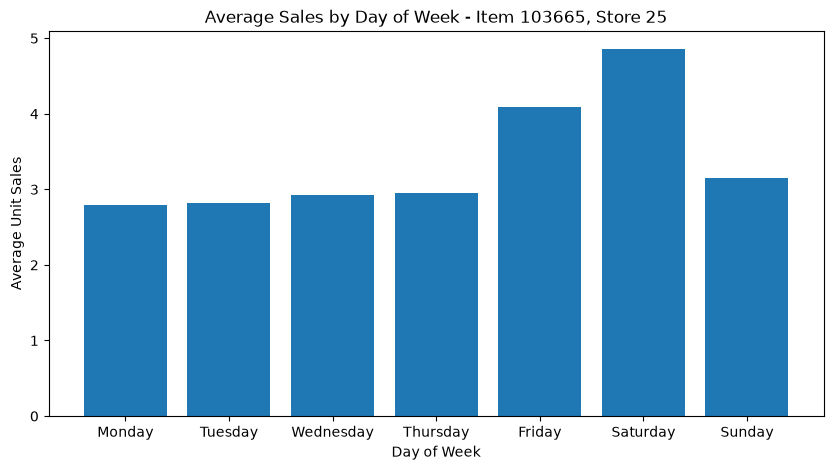

In [29]:
# Put the weekdays in normal calendar order
day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Reorder our average sales using that order
weekday_sales = weekday_sales.reindex(day_order)

# Create the bar chart
plt.figure(figsize=(10, 5))
plt.bar(weekday_sales.index, weekday_sales.values)

plt.xlabel("Day of Week")
plt.ylabel("Average Unit Sales")
plt.title("Average Sales by Day of Week - Item 103665, Store 25")

plt.show()

In [30]:
series_df["onpromotion"].value_counts(dropna=False)

onpromotion
False    771
NaN      353
True      18
Name: count, dtype: int64

In [31]:
promotion_sales = series_df.groupby("onpromotion")["unit_sales"].mean()

promotion_sales

onpromotion
False    3.326848
True     2.666667
Name: unit_sales, dtype: float64

In [32]:
# Keep only the date and sales columns for now
daily_series = series_df[["date", "unit_sales"]].copy()

# Make date the index
daily_series = daily_series.set_index("date")

# Create a row for every calendar day
daily_series = daily_series.asfreq("D")

# Look at the first 15 days
daily_series.head(15)

,unit_sales
date,
2013-01-01,7.0
2013-01-02,5.0
2013-01-03,NaN
2013-01-04,5.0
2013-01-05,5.0
2013-01-06,7.0
2013-01-07,2.0
2013-01-08,NaN
2013-01-09,NaN


In [33]:
daily_series["unit_sales"].isna().sum()

np.int64(546)

In [34]:
# Favorita omits store-item-date rows when unit_sales is zero.
# Fill the missing daily sales records with 0 observed sales.
daily_series["unit_sales"] = daily_series["unit_sales"].fillna(0)

# Verify that no missing unit_sales values remain
daily_series["unit_sales"].isna().sum()

np.int64(0)

In [35]:
# Look at rows where promotion information is missing
missing_promo = series_df[series_df["onpromotion"].isna()]

# Check the earliest and latest dates with missing promotion information
print("First missing promotion date:", missing_promo["date"].min())
print("Last missing promotion date:", missing_promo["date"].max())
print("Number of missing promotion values:", len(missing_promo))

First missing promotion date: 2013-01-01 00:00:00
Last missing promotion date: 2014-03-31 00:00:00
Number of missing promotion values: 353


In [36]:
# Sort the daily sales from oldest date to newest date
daily_series = daily_series.sort_index()

daily_series.tail(10)

,unit_sales
date,
2017-08-06,1.0
2017-08-07,0.0
2017-08-08,0.0
2017-08-09,1.0
2017-08-10,7.0
2017-08-11,6.0
2017-08-12,10.0
2017-08-13,2.0
2017-08-14,2.0


In [37]:
daily_series.head()

,unit_sales
date,
2013-01-01,7.0
2013-01-02,5.0
2013-01-03,0.0
2013-01-04,5.0
2013-01-05,5.0


In [38]:
# Everything except the final 30 days
train = daily_series.iloc[:-30]
# The final 30 days
test = daily_series.iloc[-30:]
print("Training rows:", len(train))
print("Testing rows:", len(test))

print("Training ends:", train.index.max())
print("Testing starts:", test.index.min())
print("Testing ends:", test.index.max())

Training rows: 1658
Testing rows: 30
Training ends: 2017-07-16 00:00:00
Testing starts: 2017-07-17 00:00:00
Testing ends: 2017-08-15 00:00:00


In [39]:
naive_results = test.copy()
daily_series["unit_sales"].shift(1)

date
2013-01-01     NaN
2013-01-02     7.0
2013-01-03     5.0
2013-01-04     0.0
2013-01-05     5.0
              ... 
2017-08-11     7.0
2017-08-12     6.0
2017-08-13    10.0
2017-08-14     2.0
2017-08-15     2.0
Freq: D, Name: unit_sales, Length: 1688, dtype: float64

In [40]:
naive_results = test.copy()

naive_results["prediction"] = (
    daily_series["unit_sales"].shift(1).loc[test.index]
)

naive_results.head(10)

,unit_sales,prediction
date,,
2017-07-17,3.0,0.0
2017-07-18,1.0,3.0
2017-07-19,1.0,1.0
2017-07-20,2.0,1.0
2017-07-21,3.0,2.0
2017-07-22,4.0,3.0
2017-07-23,3.0,4.0
2017-07-24,0.0,3.0
2017-07-25,0.0,0.0


In [41]:
# Calculate the absolute error for each day
naive_results["absolute_error"] = abs(
    naive_results["unit_sales"] - naive_results["prediction"]
)

# Calculate WAPE across all 30 test days
wape = (
    naive_results["absolute_error"].sum()
    / naive_results["unit_sales"].sum()
) * 100

print("Naive Forecast WAPE:", wape)

Naive Forecast WAPE: 78.57142857142857


In [42]:
# Create a new column so we keep the original onpromotion column unchanged
series_df["promotion_status"] = series_df["onpromotion"].map({
    True: "promotion",
    False: "no_promotion"
})

# Missing promotion information stays explicitly marked as unknown
series_df["promotion_status"] = series_df["promotion_status"].fillna("unknown")

# Check the result
series_df["promotion_status"].value_counts()

promotion_status
no_promotion    771
unknown         353
promotion        18
Name: count, dtype: int64

In [43]:
tft_df = daily_series.reset_index()

tft_df.head()

,date,unit_sales
0,2013-01-01,7.0
1,2013-01-02,5.0
2,2013-01-03,0.0
3,2013-01-04,5.0
4,2013-01-05,5.0


In [44]:
tft_df["time_idx"] = range(len(tft_df))

tft_df.head()

,date,unit_sales,time_idx
0,2013-01-01,7.0,0
1,2013-01-02,5.0,1
2,2013-01-03,0.0,2
3,2013-01-04,5.0,3
4,2013-01-05,5.0,4


In [45]:
tft_df["day_of_week"] = tft_df["date"].dt.day_name()

tft_df.head()

,date,unit_sales,time_idx,day_of_week
0,2013-01-01,7.0,0,Tuesday
1,2013-01-02,5.0,1,Wednesday
2,2013-01-03,0.0,2,Thursday
3,2013-01-04,5.0,3,Friday
4,2013-01-05,5.0,4,Saturday


In [48]:
tft_df["month"]=tft_df["date"].dt.month.astype(str)
tft_df.head()

,date,unit_sales,time_idx,day_of_week,month
0,2013-01-01,7.0,0,Tuesday,1
1,2013-01-02,5.0,1,Wednesday,1
2,2013-01-03,0.0,2,Thursday,1
3,2013-01-04,5.0,3,Friday,1
4,2013-01-05,5.0,4,Saturday,1


In [49]:
tft_df["year"] = tft_df["date"].dt.year

tft_df.head()

,date,unit_sales,time_idx,day_of_week,month,year
0,2013-01-01,7.0,0,Tuesday,1,2013
1,2013-01-02,5.0,1,Wednesday,1,2013
2,2013-01-03,0.0,2,Thursday,1,2013
3,2013-01-04,5.0,3,Friday,1,2013
4,2013-01-05,5.0,4,Saturday,1,2013


In [50]:
tft_df["day_of_month"] = tft_df["date"].dt.day

tft_df.head()

,date,unit_sales,time_idx,day_of_week,month,year,day_of_month
0,2013-01-01,7.0,0,Tuesday,1,2013,1
1,2013-01-02,5.0,1,Wednesday,1,2013,2
2,2013-01-03,0.0,2,Thursday,1,2013,3
3,2013-01-04,5.0,3,Friday,1,2013,4
4,2013-01-05,5.0,4,Saturday,1,2013,5


In [51]:
promotion_df = series_df[["date", "promotion_status"]]

promotion_df.head()

,date,promotion_status
0,2013-01-01,unknown
1,2013-01-02,unknown
2,2013-01-04,unknown
3,2013-01-05,unknown
4,2013-01-06,unknown


In [52]:
tft_df = tft_df.merge(
    promotion_df,
    on="date",
    how="left"
)

tft_df.head()

,date,unit_sales,time_idx,day_of_week,month,year,day_of_month,promotion_status
0,2013-01-01,7.0,0,Tuesday,1,2013,1,unknown
1,2013-01-02,5.0,1,Wednesday,1,2013,2,unknown
2,2013-01-03,0.0,2,Thursday,1,2013,3,NaN
3,2013-01-04,5.0,3,Friday,1,2013,4,unknown
4,2013-01-05,5.0,4,Saturday,1,2013,5,unknown


In [53]:
tft_df["promotion_status"] = tft_df["promotion_status"].fillna("unknown")

tft_df.head()

,date,unit_sales,time_idx,day_of_week,month,year,day_of_month,promotion_status
0,2013-01-01,7.0,0,Tuesday,1,2013,1,unknown
1,2013-01-02,5.0,1,Wednesday,1,2013,2,unknown
2,2013-01-03,0.0,2,Thursday,1,2013,3,unknown
3,2013-01-04,5.0,3,Friday,1,2013,4,unknown
4,2013-01-05,5.0,4,Saturday,1,2013,5,unknown


In [54]:
tft_df["series_id"] = "store25_item103665"

tft_df.head()

,date,unit_sales,time_idx,day_of_week,month,year,day_of_month,promotion_status,series_id
0,2013-01-01,7.0,0,Tuesday,1,2013,1,unknown,store25_item103665
1,2013-01-02,5.0,1,Wednesday,1,2013,2,unknown,store25_item103665
2,2013-01-03,0.0,2,Thursday,1,2013,3,unknown,store25_item103665
3,2013-01-04,5.0,3,Friday,1,2013,4,unknown,store25_item103665
4,2013-01-05,5.0,4,Saturday,1,2013,5,unknown,store25_item103665


In [55]:
print("Number of rows:", len(tft_df))
print("Missing values:")
print(tft_df.isnull().sum())

print("\nDuplicate dates:", tft_df["date"].duplicated().sum())

print("\nDate range:")
print(tft_df["date"].min(), "to", tft_df["date"].max())

print("\nTime index range:")
print(tft_df["time_idx"].min(), "to", tft_df["time_idx"].max())

Number of rows: 1688
Missing values:
date                0
unit_sales          0
time_idx            0
day_of_week         0
month               0
year                0
day_of_month        0
promotion_status    0
series_id           0
dtype: int64

Duplicate dates: 0

Date range:
2013-01-01 00:00:00 to 2017-08-15 00:00:00

Time index range:
0 to 1687


In [56]:
import os

train_path = "../data/favorita/favorita-grocery-sales-forecasting/train.csv"

print(os.path.exists(train_path))

True


In [58]:
test_chunk = pd.read_csv(
    train_path,
    usecols=["store_nbr", "item_nbr", "onpromotion"],
    nrows=10
)

print(test_chunk)
print(test_chunk.dtypes)

   store_nbr  item_nbr  onpromotion
0         25    103665          NaN
1         25    105574          NaN
2         25    105575          NaN
3         25    108079          NaN
4         25    108701          NaN
5         25    108786          NaN
6         25    108797          NaN
7         25    108952          NaN
8         25    111397          NaN
9         25    114790          NaN
store_nbr        int64
item_nbr         int64
onpromotion    float64
dtype: object


In [59]:
promotion_counts = {}

for chunk in pd.read_csv(
    train_path,
    usecols=["store_nbr", "item_nbr", "onpromotion"],
    dtype={
        "store_nbr": "int32",
        "item_nbr": "int32",
        "onpromotion": "string"
    },
    chunksize=500_000
):
    # Count all rows for each store-item pair
    total_counts = chunk.groupby(["store_nbr", "item_nbr"]).size()

    # Count rows where promotion is True
    promo_counts = (
        chunk[chunk["onpromotion"] == "True"]
        .groupby(["store_nbr", "item_nbr"])
        .size()
    )

    # Accumulate counts across chunks
    for key, total in total_counts.items():
        if key not in promotion_counts:
            promotion_counts[key] = {
                "total_rows": 0,
                "promotion_days": 0
            }

        promotion_counts[key]["total_rows"] += int(total)
        promotion_counts[key]["promotion_days"] += int(
            promo_counts.get(key, 0)
        )

In [60]:
len(promotion_counts)

174685

In [62]:
candidate_df = pd.DataFrame(
    [
        {
            "store_nbr": store,
            "item_nbr": item,
            "total_rows": values["total_rows"],
            "promotion_days": values["promotion_days"]
        }
        for (store, item), values in promotion_counts.items()
    ]
)

candidate_df.head()

,store_nbr,item_nbr,total_rows,promotion_days
0,1,96995,187,0
1,1,103520,1119,50
2,1,103665,1358,25
3,1,105574,1546,75
4,1,105575,1671,27


In [63]:
good_candidates = candidate_df[
    (candidate_df["total_rows"] >= 1400) &
    (candidate_df["promotion_days"] >= 50)
].copy()

good_candidates = good_candidates.sort_values(
    by="promotion_days",
    ascending=False
)

print("Number of good candidates:", len(good_candidates))

good_candidates.head(20)

Number of good candidates: 14066


,store_nbr,item_nbr,total_rows,promotion_days
41131,44,589403,1635,429
3269,3,589403,1593,416
8537,7,589403,1429,403
50572,51,589403,1581,399
47888,49,589403,1516,397
46229,48,346065,1575,377
42498,45,589403,1482,376
12909,11,323013,1551,360
11338,9,760319,1621,354
46876,48,864511,1662,353


In [64]:
selected_chunks = []

for chunk in pd.read_csv(
    train_path,
    chunksize=1_000_000
):
    selected_rows = chunk[
        (chunk["store_nbr"] == 44) &
        (chunk["item_nbr"] == 589403)
    ]

    if not selected_rows.empty:
        selected_chunks.append(selected_rows)

selected_series = pd.concat(
    selected_chunks,
    ignore_index=True
)

selected_series.head()

C:\Users\karra\AppData\Local\Temp\ipykernel_21080\2633989446.py:3: DtypeWarning: Columns (0: onpromotion) have mixed types. Specify dtype option on import or set low_memory=False.
  for chunk in pd.read_csv(


,id,date,store_nbr,item_nbr,unit_sales,onpromotion
0,32890,2013-01-02,44,589403,5.0,NaN
1,73313,2013-01-03,44,589403,3.0,NaN
2,113164,2013-01-04,44,589403,8.0,NaN
3,155274,2013-01-05,44,589403,16.0,NaN
4,197250,2013-01-06,44,589403,2.0,NaN


In [65]:
selected_series.to_csv(
    "../data/favorita/store44_item589403.csv",
    index=False
)

In [ ]:
candidate_df.to_csv(
    "../data/favorita/candidate_summary.csv",
    index=False
)